# EDA: SFOE plant register, installed PV capacity

**What the data is:** the register of all electricity production plants in Switzerland in operation, published by the Swiss Federal Office of Energy (SFOE/BFE). We use the photovoltaic plants: they give us the **installed capacity for Switzerland and Lucerne**, which turns generation into a capacity factor (G1) and transfers the national series to Lucerne (G3).

| | |
|---|---|
| Website | https://opendata.swiss/de/dataset/elektrizitatsproduktionsanlagen |
| Request used | `https://data.geo.admin.ch/ch.bfe.elektrizitaetsproduktionsanlagen/csv/2056/ch.bfe.elektrizitaetsproduktionsanlagen.zip` (script: `download_data.py`) |
| Licence | open use, source must be named ("Source: SFOE") |
| Files | `data/ElectricityProductionPlant.csv`, `PlantDetail.csv` and catalogues, downloaded 30.10.2026; large files are not versioned, `data/sample_lu_pv_first_rows.txt` shows the format |
| One row | one plant with power (kW), start date, municipality, canton, coordinates; `PlantDetail`: one part of a plant with tilt and orientation |
| Time span and resolution | snapshot of plants in operation, start dates 1989 to Sept 2026, per plant; **not a time series**. We build the capacity for 2019–2025 |
| Time zone | dates only; we build a daily capacity series in CET |

**How this notebook works:** same structure as `energy_charts_eda.ipynb`. Every section starts with a **question**, then the code, a chart where useful, and a note **Finding → Consequence**.
It follows the course EDA guide: *Step 1* validity (Q1–Q9), *Step 2* patterns and suitability (Q10–Q13). *Step 3* follows in the combined notebook.
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data")
OUT = Path("../../data/processed")   # cleaned tables for the combined notebook
FIG = Path("../../figures/eda")   # plots for the README, as required by the course guide
FIG.mkdir(parents=True, exist_ok=True)
TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
pd.set_option("display.max_columns", None)   # show all columns side by side
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"bfe_register_{name}.png", dpi=160, bbox_inches="tight")

# Step 1: Is the data valid?

## Q1: What does one raw file look like?

In [2]:
raw = pd.read_csv(DATA / "ElectricityProductionPlant.csv", dtype=str)
print("Rows:", len(raw), "| columns:", raw.shape[1])
sub = pd.read_csv(DATA / "SubCategoryCatalogue.csv", encoding="utf-8-sig", encoding_errors="replace").set_index("Catalogue_id")["en"]
print(raw["SubCategory"].map(sub).value_counts().to_string())
raw.head(3)

Rows: 341981 | columns: 14
SubCategory
Photovoltaic           339927
Hydroelectric power      1326
Biomass                   441
Natural gas               188
Wind energy                66
Waste                      28
Nuclear energy              4
Crude oil                   1


,xtf_id,Address,PostCode,Municipality,Canton,EGID,BeginningOfOperation,InitialPower,TotalPower,MainCategory,SubCategory,PlantCategory,_x,_y
0,5686,Binenweg 5,3904,Naters,VS,892091,1969-09-01,349576,349576,maincat_1,subcat_1,plantcat_7,2642480.025,1130235.125
1,5726,Robbia 2,7741,S. Carlo (Poschiavo),GR,9080323,2024-01-16,38250,38250,maincat_1,subcat_1,plantcat_4,NaN,NaN
2,5727,NaN,7744,Campocologno,GR,NaN,1907-03-01,55000,55000,maincat_1,subcat_1,plantcat_7,2808646,1123676


> **Finding:** one CSV with one row per plant and 14 columns, and all technologies in one file: 339,927 of the 341,981 plants are PV. Categories are codes (`subcat_2`) explained in separate catalogue files. Hydro plants show the unit: 349,576 kW, so power is in **kW**.
> **Consequence:** filter on `SubCategory == "subcat_2"`. Do not rely on automatic data types.

## Q2: Load the PV plants into one pandas table. Which columns and data types do we have?

In [3]:
pv = raw[raw["SubCategory"] == "subcat_2"].copy()     # subcat_2 = photovoltaic
for column in ["InitialPower", "TotalPower", "_x", "_y"]:
    pv[column] = pd.to_numeric(pv[column], errors="coerce")
pv["BeginningOfOperation"] = pd.to_datetime(pv["BeginningOfOperation"], errors="coerce")
pv = pv.drop(columns=["MainCategory", "SubCategory"])
lu = pv[pv["Canton"] == "LU"].copy()
print(f"Switzerland: {len(pv):,} plants, {pv['TotalPower'].sum() / 1e3:,.0f} MW")
print(f"Lucerne:     {len(lu):,} plants, {lu['TotalPower'].sum() / 1e3:,.0f} MW, {lu['TotalPower'].sum() / pv['TotalPower'].sum():.1%} of the capacity")
print("Date that could not be read:", pv["BeginningOfOperation"].isna().sum(), "| power that could not be read:", pv["TotalPower"].isna().sum())
pv.info()

Switzerland: 339,927 plants, 8,911 MW
Lucerne:     17,353 plants, 652 MW, 7.3% of the capacity
Date that could not be read: 0 | power that could not be read: 0
<class 'pandas.core.frame.DataFrame'>
Index: 339927 entries, 62 to 341980
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   xtf_id                339927 non-null  object        
 1   Address               337874 non-null  object        
 2   PostCode              339927 non-null  object        
 3   Municipality          339927 non-null  object        
 4   Canton                339927 non-null  object        
 5   EGID                  332575 non-null  object        
 6   BeginningOfOperation  339927 non-null  datetime64[ns]
 7   InitialPower          339927 non-null  float64       
 8   TotalPower            339927 non-null  float64       
 9   PlantCategory         335243 non-null  object        
 10  _x                  

In [4]:
pv[["InitialPower", "TotalPower"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
InitialPower,339927.0,24.5,76.3,0.0,7.9,11.9,19.4,8303.2
TotalPower,339927.0,26.2,84.2,0.2,8.1,12.2,19.9,8303.2


> **Finding:** **339,927 PV plants with 8,911 MW** in Switzerland, **17,353 plants with 652 MW** in Lucerne (7.3 %). All numbers and dates can be read. The slides still say 17,205 plants and 647 MW; the difference comes from a different download date, or a filter (not verified).
> **Consequence:** we always state the download date (30.10.2026). The size distribution is very skewed: mean 26 kW, median 12 kW, maximum 8.3 MW.

## Q3: Where are values missing, and why?

               Switzerland, %  Lucerne, %
Address                  0.60        0.40
EGID                     2.16        5.38
PlantCategory            1.38        0.81
_x                       0.71        1.58
_y                       0.71        1.58


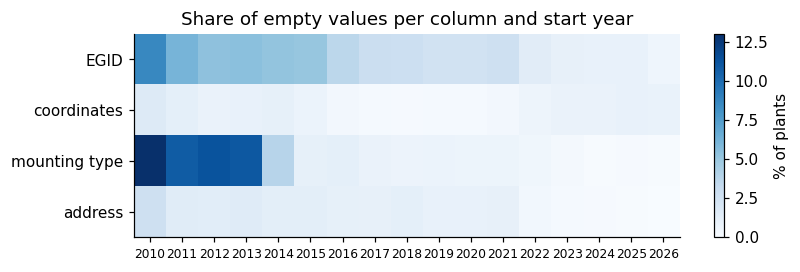

Power of Lucerne plants without coordinates: 14.6 MW


In [5]:
share = pd.DataFrame({"Switzerland, %": pv.isna().mean() * 100, "Lucerne, %": lu.isna().mean() * 100}).round(2)
print(share[share.iloc[:, 0] > 0].to_string())

# Is missing linked to the age of a plant? One flag per column, per start year (the guide's "is missing" flag)
flags = pv[["EGID", "_x", "PlantCategory", "Address"]].isna().groupby(pv["BeginningOfOperation"].dt.year).mean() * 100
flags = flags.loc[2010:2026]
fig, ax = plt.subplots(figsize=(8, 2.4))
im = ax.imshow(flags.T, aspect="auto", cmap="Blues", vmin=0, vmax=max(10, flags.values.max()))
ax.set_xticks(range(len(flags)), flags.index, fontsize=8)
ax.set_yticks(range(flags.shape[1]), ["EGID", "coordinates", "mounting type", "address"])
ax.set_title("Share of empty values per column and start year")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of plants")
save(fig, "missing_per_year")
plt.show()
print("Power of Lucerne plants without coordinates:", round(lu.loc[lu["_x"].isna(), "TotalPower"].sum() / 1e3, 1), "MW")

> **Finding:** `TotalPower`, the start date and the canton are **never empty**, so capacity per day can be computed for every plant. Empty values are in `EGID` (5.4 % in Lucerne), coordinates (1.6 %, 14.6 MW) and the mounting type. The flags show that they are spread over all start years, so this is not an effect of old plants. In Lucerne the plants without EGID are more frequent than in the rest of the country.
> **Consequence:** nothing to fill for the capacity. The 14.6 MW without coordinates are left out only when weighting the weather stations (Q11).

## Q4: Is the capacity complete? Compare the annual capacity with Energy-Charts and the official statistics

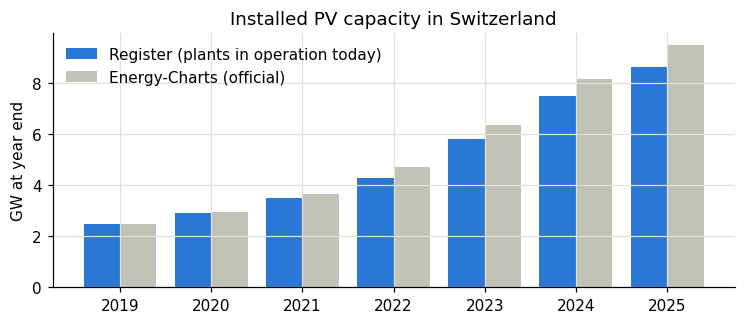

,register_GW,Energy-Charts_GW,production_GWh,register / Energy-Charts,"yield with register, kWh/kW","yield with Energy-Charts, kWh/kW"
2019,2.48,2.50,2178.0,0.99,NaN,NaN
2020,2.93,2.97,2692.0,0.99,994.22,984.10
2021,3.51,3.66,2964.0,0.96,920.48,894.39
2022,4.29,4.74,4067.0,0.90,1043.90,969.26
2023,5.83,6.38,4914.0,0.92,971.16,884.45
2024,7.50,8.17,5961.0,0.92,893.94,819.66
2025,8.63,9.50,7948.0,0.91,985.23,899.65


In [6]:
def capacity_per_day(plants):
    # cumulative MW per day; a plant counts from its start date on
    s = plants.groupby(plants["BeginningOfOperation"].dt.floor("D"))["TotalPower"].sum().cumsum() / 1000
    days = pd.date_range("2018-12-31", "2025-12-31", freq="D", name="date")   # the last day of 2018 is the starting point
    return s.reindex(s.index.union(days)).ffill().reindex(days)


capacity = pd.DataFrame({"CH_MW": capacity_per_day(pv), "LU_MW": capacity_per_day(lu)})
year_end = capacity[capacity.index.is_year_end].copy()
year_end.index = year_end.index.year

installed = json.loads((DATA / "installed_power_ch_yearly.json").read_text(encoding="utf-8"))
ec_gw = pd.Series(next(p["data"] for p in installed["production_types"] if p["name"] == "Solar DC"),
                  index=[int(y) for y in installed["time"]], name="Energy-Charts_GW")
# official Swiss PV production in GWh: Swissolar/SFOE, Statistik Sonnenenergie 2025, p. 7 (as in energy_charts_eda.ipynb)
official = pd.Series({2019: 2178, 2020: 2692, 2021: 2964, 2022: 4067, 2023: 4914, 2024: 5961, 2025: 7948}, name="production_GWh")

compare = pd.concat([(year_end["CH_MW"] / 1000).rename("register_GW"), ec_gw, official], axis=1).loc[2019:2025]
compare["register / Energy-Charts"] = compare["register_GW"] / compare["Energy-Charts_GW"]
compare["yield with register, kWh/kW"] = compare["production_GWh"] / compare["register_GW"].rolling(2).mean()
compare["yield with Energy-Charts, kWh/kW"] = compare["production_GWh"] / compare["Energy-Charts_GW"].rolling(2).mean()

fig, ax = plt.subplots(figsize=(8, 3))
x = np.arange(len(compare))
ax.bar(x - 0.2, compare["register_GW"], width=0.4, color=BLUE, label="Register (plants in operation today)")
ax.bar(x + 0.2, compare["Energy-Charts_GW"], width=0.4, color=GREY, label="Energy-Charts (official)")
ax.set_xticks(x, compare.index)
ax.set_ylabel("GW at year end")
ax.set_title("Installed PV capacity in Switzerland")
ax.legend(frameon=False)
save(fig, "capacity_vs_official")
plt.show()
compare.round(2)

> **Finding:** the register matches the official capacity until 2020 (99 %), then **falls to about 91 % from 2022 on** (8.6 instead of 9.5 GW at the end of 2025). The gap is not constant, so it matters: the yearly yield computed with the register is **about 8–10 % higher than with the official capacity from 2022 on**, while the two agree in 2020 (985 instead of 900 kWh/kW in 2025; the official statistics give about 900).
> **Consequence:** this contradicts the simple idea "the gap does not matter, we use capacity factors". A capacity factor based on the register has an artificial step around 2021–2022. When the capacity goes into the combined notebook, we should test scaling the register to the official capacity per year, and take from the register only the shape within the year and the share of Lucerne.

## Q5: Are there placeholders that are really missing values?

In [7]:
day_of_year = pv["BeginningOfOperation"].dt.strftime("%m-%d")
print("Plants that start on 1 January:", (day_of_year == "01-01").sum(), f"({(day_of_year == '01-01').mean():.2%})")
print("Most common power values (kW):", pv["TotalPower"].round(1).value_counts().head(5).to_dict())
print("Power equal to 0:", (pv["TotalPower"] == 0).sum())
details = pd.read_csv(DATA / "PlantDetail.csv", dtype=str)
for column in ["Power", "Inclination"]:
    details[column] = pd.to_numeric(details[column], errors="coerce")
print("Most common tilt values:", details["Inclination"].value_counts().head(5).to_dict())
print("Tilt equal to 0:", (details["Inclination"] == 0).sum(), "| orientation empty:", details["Orientation"].isna().sum())

Plants that start on 1 January: 223 (0.07%)
Most common power values (kW): {9.0: 3131, 12.0: 3093, 9.6: 3053, 11.2: 2939, 6.0: 2872}
Power equal to 0: 0


Most common tilt values: {10.0: 67702, 30.0: 38763, 20.0: 30421, 25.0: 25162, 35.0: 18876}
Tilt equal to 0: 2372 | orientation empty: 14119


> **Finding:** **no placeholders**: no power of 0, only 0.07 % of plants start on 1 January, and the most common sizes are round but realistic (9, 12, 9.6 kW). Tilt 0° is rare and possible (flat roofs). Round tilts such as 10° and 30° are typical mounting systems.
> **Consequence:** nothing to do.

## Q6: Time. How up to date is the register at its end?

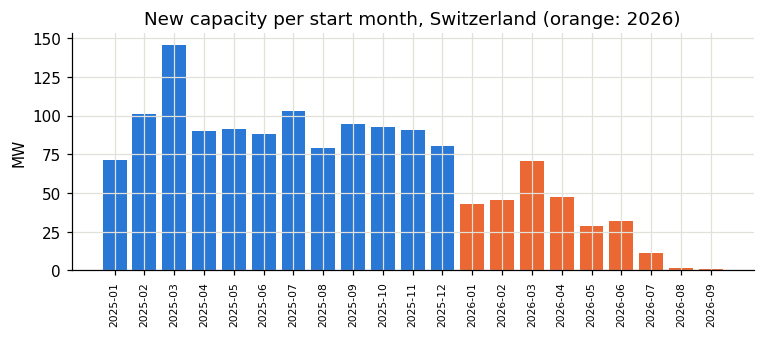

Latest start date: 2026-09-02
Extended plants: TotalPower > InitialPower: 15148 plants, 576 MW added later, but dated back to the first start


In [8]:
new_per_month = pv.groupby(pv["BeginningOfOperation"].dt.to_period("M"))["TotalPower"].sum() / 1000
last = new_per_month.loc["2025-01":]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(last.index.astype(str), last.values, color=[ORANGE if p >= pd.Period("2026-01") else BLUE for p in last.index])
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.set_ylabel("MW")
ax.set_title("New capacity per start month, Switzerland (orange: 2026)")
save(fig, "new_capacity_recent_months")
plt.show()
print("Latest start date:", pv["BeginningOfOperation"].max().date())
print("Extended plants: TotalPower > InitialPower:", (pv["TotalPower"] > pv["InitialPower"]).sum(),
      f"plants, {(pv['TotalPower'] - pv['InitialPower']).sum() / 1e3:.0f} MW added later, but dated back to the first start")

> **Finding:** new capacity is about 80–95 MW per month at the end of 2025, then **falls to 1–2 MW in the last months**. This is not a real collapse: plants are registered with a delay. Also, **576 MW** of later extensions (6.5 % of the capacity) count from the *first* start of the plant, so they are dated too early.
> **Consequence:** the register is reliable until the end of 2025, which is enough for 2019–2025, **but not for 2026**. Two errors work against each other in the past: removed plants are missing (too low) and extensions are dated too early (too high). The size of each is unknown, so we only have the check in Q4. Both are limitations.

## Q7: Are there impossible values?

In [9]:
checks = {
    "TotalPower <= 0": (lu["TotalPower"] <= 0).sum(),
    "TotalPower < 1 kW": (lu["TotalPower"] < 1).sum(),
    "TotalPower > 1 MW": (lu["TotalPower"] > 1000).sum(),
    "TotalPower < InitialPower": (lu["TotalPower"] < lu["InitialPower"]).sum(),
    "start in the future": (lu["BeginningOfOperation"] > "2026-10-29").sum(),
    "start before 2000": (lu["BeginningOfOperation"] < "2000-01-01").sum(),
    "tilt outside 0-90 degrees": ((details["Inclination"] < 0) | (details["Inclination"] > 90)).sum(),
}
print(pd.Series(checks).to_string())
lu.nlargest(5, "TotalPower")[["Municipality", "BeginningOfOperation", "TotalPower"]]

TotalPower <= 0               0
TotalPower < 1 kW             5
TotalPower > 1 MW            28
TotalPower < InitialPower     0
start in the future           0
start before 2000            17
tilt outside 0-90 degrees     0


,Municipality,BeginningOfOperation,TotalPower
25149,Perlen,2020-02-10,6425.60
81975,Altishofen,2019-10-30,2075.21
289782,Rothenburg,2025-03-19,1987.20
19446,Willisau,2021-05-20,1959.68
131832,Ebikon,2021-07-27,1940.69


> **Finding:** no zero or negative power, no start date in the future, no tilt outside 0–90° and no plant where the power was reduced. Five plants below 1 kW (balcony systems) and 28 above 1 MW. The largest is **Perlen, 6.4 MW**, a known industrial roof, not an error.
> **Consequence:** nothing removed. Very large plants are real (characteristic).

## Q8: Are plants registered twice?

In [10]:
print("Same plant id twice:", pv["xtf_id"].duplicated().sum())
key = ["Address", "PostCode", "EGID", "BeginningOfOperation", "TotalPower"]
filled = pv.dropna(subset=["Address", "EGID"])
twice = filled[filled.duplicated(key, keep=False)]
print("Same address, building, date and power:", filled.duplicated(key).sum(), "rows in Switzerland,",
      lu.dropna(subset=["Address", "EGID"]).duplicated(key).sum(), "in Lucerne")
print(f"Power of the extra rows: {filled[filled.duplicated(key)]['TotalPower'].sum() / 1e3:.1f} MW of {pv['TotalPower'].sum() / 1e3:,.0f} MW")
twice.sort_values(key).head(4)[["Address", "EGID", "BeginningOfOperation", "TotalPower"]]

Same plant id twice: 0


Same address, building, date and power: 389 rows in Switzerland, 14 in Lucerne
Power of the extra rows: 4.4 MW of 8,911 MW


,Address,EGID,BeginningOfOperation,TotalPower
267939,Aarematte 13a,191226671,2022-09-10,5.19
267943,Aarematte 13a,191226671,2022-09-10,5.19
267937,Aarematte 15a,191226710,2022-08-08,4.80
267945,Aarematte 15a,191226710,2022-08-08,4.80


> **Finding:** every plant id is unique, but 389 rows in Switzerland (14 in Lucerne) repeat address, building, date and power. They add up to 4.4 MW of 8,911 MW. Some could be true second plants on one building, so we cannot tell for sure.
> **Consequence:** keep them; the effect is 0.05 % of the capacity.

## Q9: Do the tables add up? Plant total vs. the sum of its parts

In [11]:
parts = details.groupby("ElectricityProductionPlantR")["Power"].sum().rename("parts_kW")
both = lu.set_index("xtf_id").join(parts, how="left")
print(f"Lucerne plants with details: {both['parts_kW'].notna().sum():,} of {len(both):,} ({both['parts_kW'].notna().mean():.0%}),",
      f"{both.loc[both['parts_kW'].notna(), 'TotalPower'].sum() / 1e3:.0f} MW of {both['TotalPower'].sum() / 1e3:.0f} MW")

matched = both.dropna(subset=["parts_kW"])
ratio = matched["parts_kW"] / matched["TotalPower"]
print(f"Parts equal the total (within 5 %): {ratio.between(0.95, 1.05).mean():.1%}")
print(f"Parts more than 1.5 times the total: {(ratio > 1.5).sum()} plants | less than half: {(ratio < 0.5).sum()} plants")
print("\nThe most extreme cases:")
print(matched.assign(ratio=ratio).nlargest(3, "ratio")[["Municipality", "TotalPower", "parts_kW", "ratio"]].round(1).to_string())

years = both["BeginningOfOperation"].dt.year
print("\nPlants with details per start year, %:", both["parts_kW"].notna().groupby(years).mean().mul(100).round(0).loc[2017:2026].to_dict())

Lucerne plants with details: 11,928 of 17,353 (69%), 440 MW of 652 MW
Parts equal the total (within 5 %): 95.6%
Parts more than 1.5 times the total: 115 plants | less than half: 132 plants

The most extreme cases:
            Municipality  TotalPower  parts_kW   ratio
xtf_id                                                
180490  Schwarzenberg LU         6.2    6240.0  1000.0
193088       Adligenswil        14.2   14190.0  1000.0
188272            Romoos       150.5   34960.0   232.4

Plants with details per start year, %: {2017: 0.0, 2018: 2.0, 2019: 6.0, 2020: 46.0, 2021: 98.0, 2022: 100.0, 2023: 100.0, 2024: 100.0, 2025: 100.0, 2026: 100.0}


> **Finding:**
> - Details exist for **69 % of the Lucerne plants**, but this is **not random**: nearly none before 2020, all from 2021 on (selection by age).
> - For 95.6 % of the plants the parts match the total. 115 plants have parts more than 1.5 times too large; the extreme ones are **exactly 1,000 times** the total (6,240 instead of 6.2 kW), which is a **unit error** (W instead of kW) in `PlantDetail`.
>
> **Consequence:** never sum `PlantDetail.Power` to get capacity, use `TotalPower`. Orientation and tilt describe **new plants only**, not the whole fleet.

# Step 2: Does the data contain the patterns we need?

## Q10: What does the capacity look like over time, and how are plant sizes distributed?

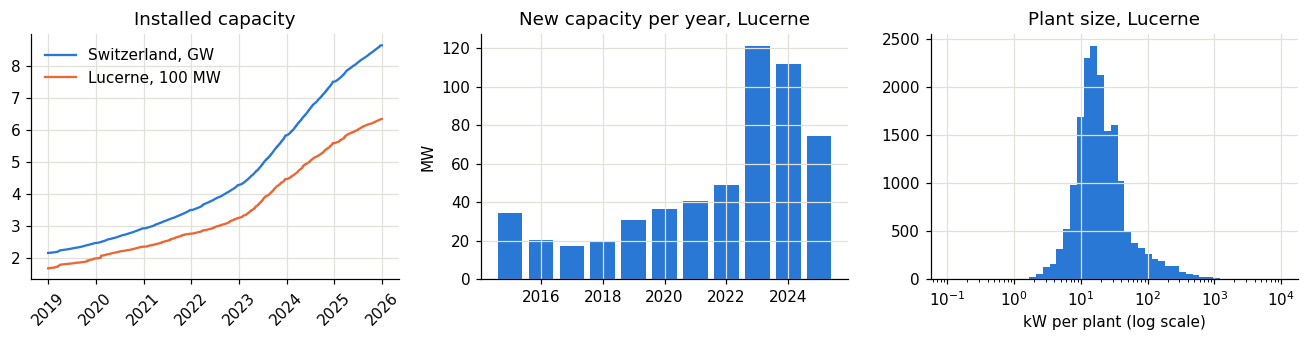

Median plant: 17.6 kW, mean: 37.6 kW
Lucerne capacity end of 2022 / end of 2025: 326.0 / 634.0 MW


,"share of plants, %","share of MW, %"
TotalPower,,
<10,18.0,3.0
10-30,57.0,27.0
30-100,18.0,24.0
100-1000,6.0,39.0
>1000,0.0,7.0


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
c = capacity.loc["2019":"2025"]
axes[0].plot(c.index, c["CH_MW"] / 1000, color=BLUE, label="Switzerland, GW")
axes[0].plot(c.index, c["LU_MW"] / 100, color=ORANGE, label="Lucerne, 100 MW")
axes[0].set_title("Installed capacity")
axes[0].legend(frameon=False)
axes[0].tick_params(axis="x", labelrotation=45)

added = lu.groupby(lu["BeginningOfOperation"].dt.year)["TotalPower"].sum() / 1000
axes[1].bar(added.loc[2015:2025].index, added.loc[2015:2025].values, color=BLUE)
axes[1].set_title("New capacity per year, Lucerne")
axes[1].set_ylabel("MW")

axes[2].hist(lu["TotalPower"], bins=np.logspace(-1, 4, 50), color=BLUE)
axes[2].set_xscale("log")
axes[2].set_xlabel("kW per plant (log scale)")
axes[2].set_title("Plant size, Lucerne")
plt.tight_layout()
save(fig, "growth_and_size")
plt.show()

size = lu.groupby(pd.cut(lu["TotalPower"], [0, 10, 30, 100, 1000, 1e5], labels=["<10", "10-30", "30-100", "100-1000", ">1000"]), observed=True)["TotalPower"].agg(["size", "sum"])
size["share of plants, %"] = size["size"] / size["size"].sum() * 100
size["share of MW, %"] = size["sum"] / size["sum"].sum() * 100
print(f"Median plant: {lu['TotalPower'].median():.1f} kW, mean: {lu['TotalPower'].mean():.1f} kW")
print("Lucerne capacity end of 2022 / end of 2025:", year_end.loc[2022, "LU_MW"].round(0), "/", year_end.loc[2025, "LU_MW"].round(0), "MW")
size[["share of plants, %", "share of MW, %"]].round(0)

> **Finding:** Lucerne's capacity **nearly doubles from 326 MW (end of 2022) to 634 MW (end of 2025)**, with a peak of new capacity in 2023 and 2024 and a slowdown in 2025. Most plants are small (75 % below 30 kW), yet the capacity sits in the larger ones: the 6 % of plants between 100 and 1,000 kW hold 39 % of the MW.
> **Consequence:** the growth is the reason why we divide by capacity, and it confirms the problem statement. We use the register as a count of MW; plant counts say little.

## Q11: Why is this dataset suitable for our goals?
Can we transfer the national series to Lucerne, and where does the capacity sit?

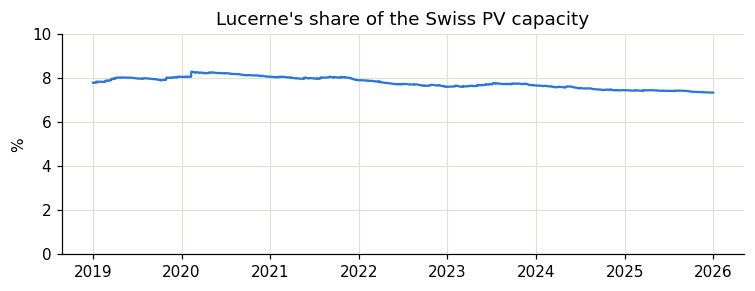

Lucerne share: 7.79 % (start of 2019) to 7.34 % (end of 2025)
Capacity closest to each station, %: {'EGO': 38.6, 'LUZ': 37.8, 'MOA': 15.2, 'SPF': 8.4}
Median distance plant to nearest station: 7.5 km


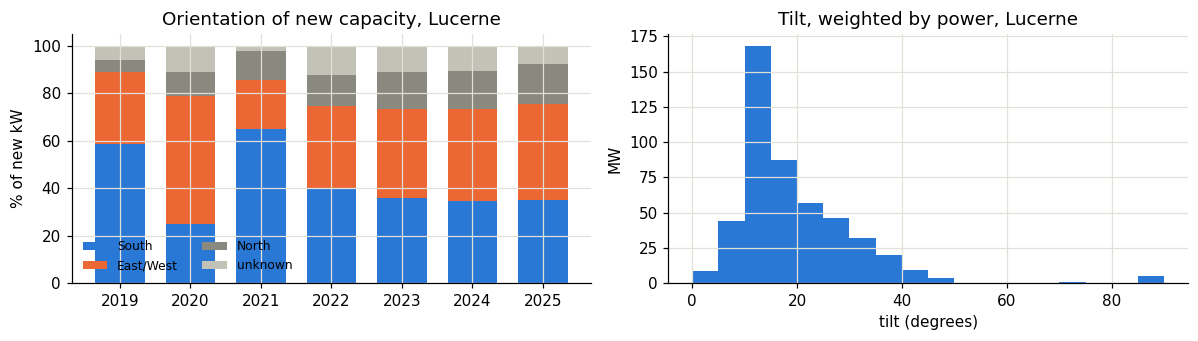

Median tilt, weighted by power: 15.0 degrees


group,East/West,North,South,unknown
year,,,,
2019,30.0,5.0,58.0,6.0
2020,54.0,10.0,25.0,11.0
2021,21.0,12.0,65.0,2.0
2022,34.0,13.0,40.0,12.0
2023,38.0,16.0,36.0,11.0
2024,39.0,16.0,35.0,11.0
2025,40.0,17.0,35.0,7.0


In [13]:
capacity["LU_share"] = capacity["LU_MW"] / capacity["CH_MW"]
fig, ax = plt.subplots(figsize=(8, 2.6))
share = capacity.loc["2019":"2025", "LU_share"] * 100
ax.plot(share.index, share.values, color=BLUE)
ax.set_ylim(0, 10)
ax.set_ylabel("%")
ax.set_title("Lucerne's share of the Swiss PV capacity")
save(fig, "lucerne_share")
plt.show()
print(f"Lucerne share: {share.iloc[0]:.2f} % (start of 2019) to {share.iloc[-1]:.2f} % (end of 2025)")

# Which weather station is closest to each plant? (register coordinates are Swiss LV95, as the station list)
meta = pd.read_csv(DATA / "ogd-smn_meta_stations.csv", sep=";", encoding="cp1252").set_index("station_abbr")
stations = meta.loc[["LUZ", "EGO", "MOA", "SPF"], ["station_coordinates_lv95_east", "station_coordinates_lv95_north"]]
located = lu.dropna(subset=["_x", "_y"])
distance = pd.DataFrame({s: np.hypot(located["_x"] - stations.loc[s].iloc[0], located["_y"] - stations.loc[s].iloc[1]) / 1000 for s in stations.index})
located = located.assign(station=distance.idxmin(axis=1), km=distance.min(axis=1))
weights = located.groupby("station")["TotalPower"].sum() / located["TotalPower"].sum()
print("Capacity closest to each station, %:", weights.mul(100).round(1).to_dict())
print(f"Median distance plant to nearest station: {located['km'].median():.1f} km")

# Orientation: it changes the shape of the daily curve
names = pd.read_csv(DATA / "OrientationCatalogue.csv", encoding="utf-8-sig").set_index("Catalogue_id")["en"]
part = details[details["ElectricityProductionPlantR"].isin(lu["xtf_id"])].copy()
part["group"] = part["Orientation"].map(names).replace({"Southeast": "South", "Southwest": "South", "East": "East/West", "West": "East/West",
                                                         "Northeast": "North", "Northwest": "North", "North": "North"}).fillna("unknown")
part["year"] = pd.to_datetime(part["Date"], errors="coerce").dt.year
mix = part[part["year"].between(2019, 2025)].pivot_table(index="year", columns="group", values="Power", aggfunc="sum")
mix = mix.div(mix.sum(axis=1), axis=0) * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
bottom = np.zeros(len(mix))
for group, colour in zip(["South", "East/West", "North", "Zenith", "unknown"], [BLUE, ORANGE, "#8a897f", "#7fb0e8", GREY]):
    if group in mix:
        axes[0].bar(mix.index, mix[group], bottom=bottom, color=colour, label=group, width=0.7)
        bottom += mix[group].values
axes[0].set_title("Orientation of new capacity, Lucerne")
axes[0].set_ylabel("% of new kW")
axes[0].legend(frameon=False, ncol=2, fontsize=8)
axes[1].hist(part["Inclination"], bins=range(0, 95, 5), weights=part["Power"] / 1000, color=BLUE)
axes[1].set_title("Tilt, weighted by power, Lucerne")
axes[1].set_xlabel("tilt (degrees)")
axes[1].set_ylabel("MW")
plt.tight_layout()
save(fig, "orientation_tilt")
plt.show()
ordered = part.sort_values("Inclination")
print("Median tilt, weighted by power:", ordered.loc[ordered["Power"].cumsum() >= ordered["Power"].sum() / 2, "Inclination"].iloc[0], "degrees")
mix.round(0)

> **Finding:**
> - **Lucerne's share falls slowly from 7.8 % to 7.3 %.** It is stable enough to transfer the national series, but not constant.
> - The capacity is unevenly spread: **Egolzwil and Luzern each represent about 38 %**, Mosen 15 % and Schüpfheim only 8 %. Half of the plants are within 7.5 km of a station.
> - Since 2023, about **40 % of the new capacity faces east or west** and only 35 % south (including south-east and south-west). The median tilt is 15° (many flat roofs). (2019–2020 rest on few plants, see Q9.)
>
> **Consequence:** suitable for G1 and G3. We weight the stations by capacity, not equally. East/west plants flatten the midday peak, so the daily shape may change over the years; this is worth checking in Step 3.

## Q12: Leakage. Which information will not exist at prediction time?

In [14]:
# The capacity of a past day, seen from today, contains plants registered later.
print("Capacity at the start of the test year, seen from the snapshot of today:")
print(f"  Switzerland 2025-01-01: {capacity.loc['2025-01-01', 'CH_MW']:,.0f} MW")
print(f"  Added during the test year 2025: {capacity.loc['2025-12-31', 'CH_MW'] - capacity.loc['2025-01-01', 'CH_MW']:,.0f} MW")

Capacity at the start of the test year, seen from the snapshot of today:
  Switzerland 2025-01-01: 7,504 MW
  Added during the test year 2025: 1,128 MW


> **Finding:** the register is a snapshot from October 2026. Seen from a forecast made in 2025, it contains plants that were only registered later. During the test year the capacity grows by 1,128 MW (15 %).
> **Consequence:** in G3, use the capacity of the day *before* the forecast. A small leak remains, because of late registrations. A real forecast would have to estimate the current capacity. We state this as a limitation.

## Q13: Baseline. What would a very simple estimate of the Lucerne capacity score?

In [15]:
ye = year_end.loc[2020:2025]
share_2019 = year_end.loc[2019, "LU_MW"] / year_end.loc[2019, "CH_MW"]
errors = pd.DataFrame({
    "real LU_MW": ye["LU_MW"],
    "fixed share of 2019": ye["CH_MW"] * share_2019,
    "same as previous year": year_end["LU_MW"].shift(1).loc[2020:2025],
})
mape = (errors.drop(columns="real LU_MW").sub(errors["real LU_MW"], axis=0).abs().div(errors["real LU_MW"], axis=0) * 100).mean().round(1)
print("Mean error in %:", mape.to_dict())
errors.round(0)

Mean error in %: {'fixed share of 2019': 5.1, 'same as previous year': 17.3}


,real LU_MW,fixed share of 2019,same as previous year
date,,,
2020,237.0,236.0,200.0
2021,277.0,282.0,237.0
2022,326.0,345.0,277.0
2023,447.0,470.0,326.0
2024,559.0,605.0,447.0
2025,634.0,696.0,559.0


> **Finding:** assuming the Lucerne share of 2019 stays fixed misses Lucerne's capacity by about 5 % on average, and by 10 % in 2025 (696 instead of 634 MW). Taking last year's value misses it by 17 %.
> **Consequence:** the register is needed, a fixed share is not good enough. These errors are the yardstick for the transfer to Lucerne.

## Save the cleaned tables for later use in the combined notebook

In [16]:
OUT.mkdir(parents=True, exist_ok=True)
capacity.to_csv(OUT / "capacity_daily.csv")
weights.rename("weight").to_csv(OUT / "station_weights.csv")
print(capacity.loc[["2019-01-01", "2025-12-31"]].round(3).to_string())

               CH_MW    LU_MW  LU_share
date                                   
2019-01-01  2170.959  169.202     0.078
2025-12-31  8631.115  633.731     0.073


# Summary

## Decision log

| # | Issue | Error or characteristic? | Decision | Affected |
|---|---|---|---|---|
| Q1 | All technologies in one file, codes instead of names | characteristic | filter on `subcat_2` | 2,054 rows dropped |
| Q3 | No EGID, no coordinates | characteristic | not filled; not needed for the capacity | LU: 934 and 275 plants |
| Q4 | Register only about 91 % of the official capacity from 2022 on | **error** of coverage (not constant) | test scaling to the official capacity per year | 2022–2025 |
| Q6 | Last months incomplete (late registration) | characteristic | do not use capacity after 2025 | 2026 |
| Q6 | Extensions counted from the first start date | characteristic | `TotalPower` kept, stated as a limitation | 576 MW in CH |
| Q6 | Removed plants are missing (survivorship) | characteristic | stated as a limitation | unknown |
| Q8 | Possible double entries | unclear | kept | 389 rows, 4.4 MW |
| Q9 | `PlantDetail.Power` 1,000 times too large in some rows | **error** | `PlantDetail` not used for capacity | at least 115 plants in LU |
| Q9 | Tilt and orientation mostly missing before 2021 | characteristic (selection by age) | only described for new plants | 31 % of plants in LU |
| Q11 | Capacity unevenly spread over the stations | characteristic | capacity-weighted station mean | – |
| Q12 | Snapshot contains later registrations | leakage risk (small) | use the capacity of the previous day, state it | test year |

## Is the data suitable? (Insights)

**Yes for the capacity of Lucerne and its growth, only partly as an absolute level.** Power and start date are complete and plausible for every plant. Limits: it is a snapshot and not a history, it covers only about 91 % of the official capacity from 2022 on, and 2026 is incomplete.

## Open questions (to discuss)

1. Scale the register to the official capacity per year (recommended by Q4), or accept the step in the capacity factor? (To be tested in the combined notebook.)
2. Does Elias's "installed capacity" for the national capacity factor come from the register or from Energy-Charts? We need to use one definition.
3. Update the plant numbers in the pitch (17,205 / 647 MW) with the download date.

## Next steps (Step 3 of the guide)

- Cleaned tables: `data/processed/capacity_daily.csv`, `data/processed/station_weights.csv`.
- Combined notebook: add the capacity factor and the capacity-weighted radiation.